In [27]:
import os
import json
import time
import hashlib
import joblib

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, FunctionTransformer

from sklearn.metrics import (
    root_mean_squared_error,
    mean_absolute_error,
    median_absolute_error,
    r2_score
)

from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

from lightgbm import LGBMRegressor
from catboost import CatBoostRegressor
from xgboost import XGBRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import ElasticNet, Ridge

In [33]:
DATA_PATH = "../data/processed/sparcs_2024_final.parquet"

df = pd.read_parquet(DATA_PATH).reset_index(drop=True)

POST_ADMISSION = [
    "ccsr_diagnosis_code",
    "apr_medical_surgical",
    "ccsr_procedure_code"
]

TARGET = "los"

# Admission features only
ADMISSION = [
    col for col in df.columns
    if col not in POST_ADMISSION + [TARGET]
]

ORDINAL_FTRS = ["age_group"]

ORDINAL_CATS = [
    ["0-17", "18-29", "30-49", "50-69", "70 or Older"]
]

CATEGORICAL_FTRS = [
    col for col in ADMISSION + POST_ADMISSION
    if col not in ORDINAL_FTRS
]

CONTINUOUS_FTRS = []

#Interaction features
INTERACTION_CANDIDATES = [
    ("type_of_admission", "age_group"),
    ("type_of_admission", "race"),
]

# EXPERIMENT SETTINGS

PCT = 0.01
N_STATES = 3
N_FOLDS = 5
TEST_SIZE = 0.005
RANDOM_STATE = 42
RANDOM_STATES = [RANDOM_STATE * i for i in range(1, N_STATES + 1)]  # 42, 84, 126
LOS_BINS = [0, 1, 2, 3, 5, 7, 14, 30, 120]

# OUTPUT DIRECTORIES
OUTPUT_DIR = "../results/los_learning_curve"

SPLIT_DIR = os.path.join(OUTPUT_DIR, "shared")
MODEL_DIR = os.path.join(OUTPUT_DIR, "models")
RESULT_DIR = os.path.join(OUTPUT_DIR, "results")
PREDICTION_DIR = os.path.join(OUTPUT_DIR, "predictions")

for folder in [
    SPLIT_DIR,
    MODEL_DIR,
    RESULT_DIR,
    PREDICTION_DIR
]:
    os.makedirs(folder, exist_ok=True)


# Basic checks
X = df[ADMISSION].copy()
y = df[TARGET].copy()

assert y.notna().all(), "The target contains missing values."
assert X.columns.tolist() == ADMISSION

print("Dataset shape:", df.shape)
print("Number of admission features:", len(ADMISSION))
print("Admission features:", ADMISSION)
print("Target:", TARGET)
print("Output directory:", OUTPUT_DIR)

Dataset shape: (1993483, 15)
Number of admission features: 11
Admission features: ['permanent_facility_id', 'age_group', 'zip_code', 'gender', 'race', 'ethnicity', 'type_of_admission', 'payment_typology_1', 'emergency_department_indicator', 'payment_typology_2', 'payment_typology_3']
Target: los
Output directory: ../results/los_learning_curve


In [14]:
def get_los_bins(y):
    #Assign LOS observations to stratification bins.
    bins = pd.cut(y, bins=LOS_BINS, labels=False, include_lowest=True)
    if bins.isna().any():
        raise ValueError(
            "Some LOS values fall outside LOS_BINS. "
            "Check the target range and bin boundaries."
        )

    return bins

def get_data_fingerprint(path):
    #Generate a SHA256 fingerprint of the source dataset.
    sha256 = hashlib.sha256()
    with open(path, "rb") as f:
        for chunk in iter(lambda: f.read(1024 * 1024), b""):
            sha256.update(chunk)

    return sha256.hexdigest()

DATA_FINGERPRINT = get_data_fingerprint(DATA_PATH)

In [15]:
def add_interactions(X, features):
    """Add one combined categorical column per candidate pair whose features are both used"""
    X= X.copy()
    interaction_ftrs = []

    for a, b in INTERACTION_CANDIDATES:
        if a in features and b in features:
            name = f"{a}_x_{b}"
            X[name]= X[a].astype(str)+"|"+ X[b].astype(str)
            interaction_ftrs.append(name)
        
    return X, interaction_ftrs

In [16]:
def get_split(random_state):
    """Stratified train_val/test split for one random state.
    Saved so every algorithm uses the same split for the same random state."""
    split_path = os.path.join(SPLIT_DIR, f"test_split_rs{random_state}.joblib")

    if os.path.exists(split_path):
        split_data = joblib.load(split_path)
        assert split_data["data_fingerprint"] == DATA_FINGERPRINT, (
            "The dataset does not match the dataset used to create the saved split.")
        assert split_data["test_size"] == TEST_SIZE
        assert split_data["target"] == TARGET
    else:
        train_idx, test_idx = train_test_split(
            np.arange(len(df)),
            test_size=TEST_SIZE,
            stratify=get_los_bins(y),
            random_state=random_state
        )
        split_data = {
            "train_idx": train_idx,
            "test_idx": test_idx,
            "data_fingerprint": DATA_FINGERPRINT,
            "target": TARGET,
            "test_size": TEST_SIZE,
            "random_state": random_state
        }
        joblib.dump(split_data, split_path)

    return split_data["train_idx"], split_data["test_idx"]


for rs in RANDOM_STATES:
    train_idx, test_idx = get_split(rs)
    print(f"random state {rs:>3} | train_val {len(train_idx):,} | test {len(test_idx):,} ({len(test_idx) / len(df):.2%})")

random state  42 | train_val 1,983,515 | test 9,968 (0.50%)
random state  84 | train_val 1,983,515 | test 9,968 (0.50%)
random state 126 | train_val 1,983,515 | test 9,968 (0.50%)


In [17]:
def create_subset(y_train_val, pct, random_state=RANDOM_STATE):
    #Create a nested, stratified subset of train_val.
    rng = np.random.default_rng(random_state)
    train_bins = get_los_bins(y_train_val).to_numpy()
    selected = []
    for bin_label in np.unique(train_bins):
        idx = np.where(train_bins == bin_label)[0]
        shuffled_idx = rng.permutation(idx)
        n_select = max(1, int(round(len(idx) * pct)))
        selected.extend(shuffled_idx[:n_select])

    return np.array(selected, dtype=int)

In [18]:
def make_preprocessor(features, interaction_ftrs=None):
    if interaction_ftrs is None:
        interaction_ftrs = []
    ordinal_features = [col for col in features if col in ORDINAL_FTRS]
    onehot_features = [col for col in features if col not in ORDINAL_FTRS] + interaction_ftrs
    transformers = []
    if ordinal_features:
        ordinal_categories = [ORDINAL_CATS[ORDINAL_FTRS.index(col)] for col in ordinal_features]
        transformers.append(("ordinal", OrdinalEncoder(categories=ordinal_categories,
                                                       handle_unknown="use_encoded_value", 
                                                       unknown_value=-1), ordinal_features))
    if onehot_features:
        transformers.append(("onehot", OneHotEncoder(handle_unknown="ignore"), onehot_features))
        
    return ColumnTransformer(transformers=transformers, remainder="drop")

In [19]:
def build_model(model_name, features, interaction_ftrs=None, random_state=RANDOM_STATE):

    if interaction_ftrs is None:
        interaction_ftrs = []

    if model_name == "svr":

        model = Pipeline([
            ("preprocessor", make_preprocessor(features, interaction_ftrs)),
            ("model", SVR())
        ])

        param_grid = {
            "model__C": [0.1, 1, 10],
            "model__epsilon": [0.1, 0.5, 1.0],
            "model__kernel": ["rbf"]
        }

    elif model_name == "lightgbm":

        model = Pipeline([
            ("preprocessor", make_preprocessor(features, interaction_ftrs)),
            ("model", LGBMRegressor(
                random_state=random_state,
                n_jobs=1,
                verbosity=-1
            ))
        ])

        param_grid = {
            "model__n_estimators": [100, 300, 500],
            "model__num_leaves": [15, 31],
            "model__learning_rate": [0.05, 0.07, 0.1]
        }

    elif model_name == "catboost":

        model = CatBoostRegressor(
            random_seed=random_state,
            verbose=0,
            thread_count=1,
            iterations=2000,
            early_stopping_rounds=50,
            allow_writing_files=False
        )

        param_grid = {
            "depth": [4, 6],
            "learning_rate": [0.03, 0.07, 0.1],
            "l2_leaf_reg": [3, 5]
        }

    elif model_name == "knn":

        model = Pipeline([
            ("preprocessor", make_preprocessor(features, interaction_ftrs)),
            ("model", KNeighborsRegressor(
                algorithm="brute",
                n_jobs=1
            ))
        ])

        param_grid = {
            "model__n_neighbors": [5, 10, 20, 40],
            "model__weights": ["uniform", "distance"],
            "model__p": [1, 2]
        }
    elif model_name =="ridge":
        model = Pipeline([
            ("preprocessor", make_preprocessor(features,interaction_ftrs)),
            ("model",Ridge())
        ])
        param_grid ={
                    "model__alpha": np.logspace(-1, 5, 7),
                }
    elif model_name =="elastic":
        model = Pipeline([
            ("preprocessor", make_preprocessor(features,interaction_ftrs)),
            ("model",ElasticNet())
        ])
        param_grid ={
                    "model__alpha": np.logspace(-3, 0, 7),
                    "model__l1_ratio": [0.1, 0.5, 1.0],
                    "model__max_iter": [10000],
        }
    elif model_name =="rf":
        model = Pipeline([
            ("preprocessor", make_preprocessor(features,interaction_ftrs)),
            ("model",RandomForestRegressor(random_state=random_state))
        ])
        param_grid ={
            "model__max_depth": [10, 20, 30],
            "model__max_features": [0.5, 0.75, 1.0],
            "model__n_estimators": [100],
            "model__n_jobs": [1],
        }
    elif model_name=="xgb":
        model = Pipeline([
            ("preprocessor", make_preprocessor(features,interaction_ftrs)),
            ("model",XGBRegressor(random_state=random_state))
        ])
        param_grid ={
            "model__max_depth": [3, 6, 10],
            "model__colsample_bytree": [0.5, 0.9],
            "model__learning_rate": [0.1],
            "model__n_estimators": [10000],         # upper limit, early stopping picks the number of trees
            "model__early_stopping_rounds": [50],   # not tuned but value is preserved in returned best_params
            "model__n_jobs": [-1],                  # the early stopping loop runs one fit at a time
        }
    else:
        raise ValueError(f"Unknown model: {model_name}")

    return model, param_grid

In [20]:
def calculate_metrics(y_true, y_pred):
    return {
        "rmse": root_mean_squared_error(y_true, y_pred),
        "mae": mean_absolute_error(y_true, y_pred),
        "median_ae": median_absolute_error(y_true, y_pred),
        "r2": r2_score(y_true, y_pred)
    }

In [21]:
from joblib import parallel_backend
from sklearn.base import clone
from sklearn.model_selection import ParameterGrid

#models we use early stopping for. Cannot use gridsearch due to the fit method
EARLY_STOPPING_MODELS = (XGBRegressor, CatBoostRegressor)


def get_estimator(model):
    """The ML model itself, whether or not it is inside a preprocessing pipeline"""
    return model.named_steps["model"] if isinstance(model, Pipeline) else model


def get_best_iteration(estimator):
    """Makes the call to the best_iteration method for the early stopping model"""
    if isinstance(estimator, XGBRegressor):
        return estimator.best_iteration
    #else catboost
    return estimator.get_best_iteration()  


def set_n_trees(model, n_trees):
    """To allow refitting the model with validation set, use the n_trees from early stopping trained with validation set"""
    if isinstance(get_estimator(model), XGBRegressor):
        prefix = "model__" if isinstance(model, Pipeline) else "" #if the model is pipeline with preprocessing
        params = {f"{prefix}n_estimators": n_trees, f"{prefix}early_stopping_rounds": None}
        model.set_params(**params)
    else:
        model.set_params(iterations=n_trees, early_stopping_rounds=None)
    return model

def early_stopping_cross_validation(model, param_grid, X_train, y_train, X_test, y_test,random_state=RANDOM_STATE, fit_params=None):
    """
    KFold cross validation similar to GridSearchCV but the validation set is used as the eval set for early stopping.
    The preprocessor is fit only on the training folds.
    """
    fit_params = {} if fit_params==None else fit_params
    kf = KFold(n_splits=N_FOLDS,shuffle=True,random_state=random_state)

    candidates = []
    for params in ParameterGrid(param_grid):
        fold_metrics=None
        fold_trees=[]
        for train_folds, val_fold in kf.split(X_train):
            X_train_fold=X_train.iloc[train_folds]
            X_val_fold = X_train.iloc[val_fold]
            y_train_fold = y_train.iloc[train_folds]
            y_val_fold = y_train.iloc[val_fold]
            f_model = clone(model).set_params(**params)

            #extract the preprocessing from pipeline. We cannot use fit since preprocessing would ignore validation set
            if isinstance(f_model,Pipeline):
                preprocessing=f_model.named_steps["preprocessor"]
                X_tr = preprocessing.fit_transform(X_train_fold)
                X_val = preprocessing.transform(X_val_fold)
            else:
                X_tr=X_train_fold
                X_val=X_val_fold
            f_model = get_estimator(f_model)
            f_model.fit(X_tr,y_train_fold,eval_set=[(X_val,y_val_fold)],verbose=False,**fit_params)
            if not fold_metrics:
                fold_metrics = calculate_metrics(y_val_fold,f_model.predict(X_val))
            else:
                next_fold_metrics = calculate_metrics(y_val_fold,f_model.predict(X_val))
                for key in fold_metrics.keys():
                    fold_metrics[key]+=next_fold_metrics[key]
            fold_trees.append(get_best_iteration(f_model)+1)
        #The best number of trees is the average across folds
        for key in fold_metrics.keys():
            fold_metrics[key]/=N_FOLDS
        candidates.append({"params":params,"cv_metrics":fold_metrics,"n_trees":int(round(np.mean(fold_trees)))})
    best = min(candidates,key=lambda cand: cand["cv_metrics"]["rmse"])#find min rmse of the model hyperparameters
    best_model = set_n_trees(clone(model).set_params(**best["params"]),best["n_trees"])
    best_model.fit(X_train,y_train,**fit_params) #refit with full train. The early stopping parameter is removed since we have n_trees from cv
    best_params = best["params"]
    best_params["n_trees"]=best["n_trees"]

    y_test_pred = best_model.predict(X_test)
    test_metrics = calculate_metrics(y_test,y_test_pred)
    return (best_model, best_params, best["cv_metrics"],
                test_metrics, y_test_pred)

def cross_validation(model, param_grid, X_train, y_train, X_test, y_test, 
                     random_state=RANDOM_STATE,fit_params=None):
    if isinstance(get_estimator(model),EARLY_STOPPING_MODELS):
        return early_stopping_cross_validation(model, param_grid, X_train,y_train, X_test, y_test,random_state=random_state,fit_params=fit_params)

    kf = KFold(n_splits=N_FOLDS, shuffle=True, random_state=random_state)
    scoring = {
        "rmse": "neg_root_mean_squared_error",
        "mae": "neg_mean_absolute_error",
        "median_ae": "neg_median_absolute_error",
        "r2": "r2"
    }
    grid = GridSearchCV(
        estimator=model,
        param_grid=param_grid,
        scoring=scoring,
        refit="rmse",
        cv=kf,
        return_train_score=True,
        n_jobs=-1
    )
    # threads share memory, so no worker processes get recycled
    with parallel_backend("threading"):
        grid.fit(X_train, y_train, **(fit_params or {}))

    best_model = grid.best_estimator_
    best_idx = grid.best_index_

    cv_metrics = {
        "rmse": -grid.cv_results_["mean_test_rmse"][best_idx],
        "mae": -grid.cv_results_["mean_test_mae"][best_idx],
        "median_ae": -grid.cv_results_["mean_test_median_ae"][best_idx],
        "r2": grid.cv_results_["mean_test_r2"][best_idx]
    }

    test_predictions = best_model.predict(X_test)
    test_metrics = calculate_metrics(y_test, test_predictions)

    return (best_model, grid.best_params_, cv_metrics,
            test_metrics, test_predictions)


In [22]:
def get_experiment_suffix(use_interactions):
    return "interactions" if use_interactions else "no_interactions"

def get_file_stem(model_name, pct, use_interactions, random_state):
    return f"{model_name}_pct_{pct:g}_{get_experiment_suffix(use_interactions)}_rs{random_state}"

def save_model(best_model, model_name, pct, use_interactions, random_state, best_params,
               cv_metrics, test_metrics, model_features, interaction_ftrs):

    algorithm_dir = os.path.join(MODEL_DIR, model_name)
    os.makedirs(algorithm_dir, exist_ok=True)
    filename = get_file_stem(model_name, pct, use_interactions, random_state) + ".joblib"

    model_path = os.path.join(algorithm_dir, filename)
    joblib.dump(best_model, model_path)

    metadata = {
        "algorithm": model_name,
        "pct": pct,
        "use_interactions": use_interactions,
        "random_state": random_state,
        "features": model_features,
        "interaction_features": interaction_ftrs,
        "best_params": {
            key: str(value)
            for key, value in best_params.items()
        },
        "cv_metrics": cv_metrics,
        "test_metrics": test_metrics,
        "data_fingerprint": DATA_FINGERPRINT,
        "test_random_state": random_state,
        "subset_random_state": random_state,
        "cv_random_state": random_state,
        "n_folds": N_FOLDS,
        "model_path": model_path
    }

    metadata_path = model_path.replace(".joblib", "_metadata.json")

    with open(metadata_path, "w") as f:
        json.dump(metadata, f, indent=4)

    return model_path

In [23]:
RESULT_COLUMNS = [
    "algorithm",
    "pct",
    "use_interactions",
    "random_state",
    "interaction_features",
    "n_train",
    "n_test",
    "actual_pct_train_val",
    "actual_pct_original",

    "cv_rmse",
    "cv_mae",
    "cv_median_ae",
    "cv_r2",

    "test_rmse",
    "test_mae",
    "test_median_ae",
    "test_r2",

    "best_params",
    "training_time_sec",
    "model_path",
    "prediction_path",

    "test_random_state",
    "subset_random_state",
    "cv_random_state",
    "data_fingerprint"
]


def read_results(model_name):
    """Read an algorithm's results file (empty table if there is none yet)"""
    result_path = os.path.join(RESULT_DIR, f"results_{model_name}.csv")
    if not os.path.exists(result_path):
        return pd.DataFrame(columns=RESULT_COLUMNS)
    results = pd.read_csv(result_path)
    return results


def same_experiment(results, pct, use_interactions, random_state):
    #check if the row is same based on pct used and interaction features and random_stae
    return (np.isclose(results["pct"].astype(float), pct)& (results["use_interactions"].astype(str) == str(use_interactions))
            & (results["random_state"].astype(int) == random_state))


def result_exists(model_name, pct, use_interactions, random_state):
    results = read_results(model_name)
    return bool(same_experiment(results, pct, use_interactions, random_state).any())


def save_result(result):
    model_name = result["algorithm"]
    result_path = os.path.join(RESULT_DIR, f"results_{model_name}.csv")

    old_results = read_results(model_name)
    old_results = old_results.loc[~same_experiment(
        old_results, result["pct"], result["use_interactions"], result["random_state"])]

    results = pd.concat([old_results, pd.DataFrame([result])], ignore_index=True)
    results = results[RESULT_COLUMNS].sort_values(["pct", "use_interactions", "random_state"])
    results.to_csv(result_path, index=False)

    return result_path

In [24]:
def run_experiment(model_name, pct, features=ADMISSION, use_interactions=False,
                   random_states=RANDOM_STATES, skip_existing=True):
    """
    Train one algorithm at one PCT for every random state.

    Each random state gets its own train/test split, training subset and CV folds,
    so the spread of the scores includes the uncertainty due to splitting.

    Parameters
    ----------
    model_name : str
        "svr", "lightgbm", "catboost", or "knn".
    pct : float
        Training percentage of train_val.
    features : list
        Features to use.
    use_interactions : bool
        Whether to create interaction features.
    random_states : list
        Random states to run.
    skip_existing : bool
        Skip random states that are already in the results file.

    Saves
    -----
    Fitted model, metadata, predictions, and one result row per random state.
    Returns the list of result rows that were run.
    """

    # Select features and optionally add interactions
    X_all = df[features].copy()
    if use_interactions:
        X_all, interaction_ftrs = add_interactions(X_all, features)
    else:
        interaction_ftrs = []

    model_features = features + interaction_ftrs

    results = []
    for random_state in random_states:

        print("\n" + "=" * 75)
        print(f"Algorithm: {model_name.upper()} | Training PCT: {pct:.1%} | "
              f"Interactions: {use_interactions} | Random state: {random_state}")
        print("=" * 75)

        if skip_existing and result_exists(model_name, pct, use_interactions, random_state):
            print("Already in the results file, skipping.")
            continue

        #new split for every random state
        train_idx, test_idx = get_split(random_state)

        X_train_val = X_all.iloc[train_idx].copy()
        X_test_model = X_all.iloc[test_idx].copy()

        y_train_val = y.iloc[train_idx].copy()
        y_test = y.iloc[test_idx].copy()

        # Create the reproducible training subset
        subset_idx = create_subset(y_train_val, pct, random_state=random_state)

        X_train = X_train_val.iloc[subset_idx].copy()
        y_train = y_train_val.iloc[subset_idx].copy()

        actual_pct_train_val = len(X_train) / len(X_train_val)
        actual_pct_original = len(X_train) / len(df)

        print(f"Training observations: {len(X_train):,}")
        print(f"Test observations: {len(X_test_model):,}")
        print(f"Actual train_val percentage: {actual_pct_train_val:.2%}")
        print(f"Actual original-data percentage: {actual_pct_original:.2%}")

        print(f"Features used: {len(model_features)}")
        print(f"Interaction features: {interaction_ftrs or 'None'}")

        # Build model and parameter grid
        model, param_grid = build_model(
            model_name=model_name,
            features=features,
            interaction_ftrs=interaction_ftrs,
            random_state=random_state)

        fit_params = {}

        if model_name == "catboost":
            fit_params["cat_features"] = model_features

        # Cross-validation and hyperparameter tuning
        start_time = time.time()

        (   best_model,
            best_params,
            cv_metrics,
            test_metrics,
            test_predictions
        ) = cross_validation(
            model=model,
            param_grid=param_grid,
            X_train=X_train,
            y_train=y_train,
            X_test=X_test_model,
            y_test=y_test,
            random_state=random_state,
            fit_params=fit_params
        )

        elapsed = time.time() - start_time

        # Save fitted model
        model_path = save_model(
            best_model=best_model,
            model_name=model_name,
            pct=pct,
            use_interactions=use_interactions,
            random_state=random_state,
            best_params=best_params,
            cv_metrics=cv_metrics,
            test_metrics=test_metrics,
            model_features=model_features,
            interaction_ftrs=interaction_ftrs
        )

        # Save test predictions
        prediction_filename = get_file_stem(model_name, pct, use_interactions, random_state) + "_predictions.csv"
        prediction_path = os.path.join(PREDICTION_DIR, prediction_filename)

        predictions_df = pd.DataFrame({
            "row_index": test_idx,
            "y_true": y_test.to_numpy(),
            "y_pred": np.asarray(test_predictions)
        })

        predictions_df["residual"] = (predictions_df["y_true"] - predictions_df["y_pred"])
        predictions_df["absolute_error"] = (predictions_df["residual"].abs())

        predictions_df.to_csv(prediction_path, index=False)

        # Build result record
        result = {
            "algorithm": model_name,
            "pct": pct,
            "use_interactions": use_interactions,
            "random_state": random_state,
            "interaction_features": json.dumps(interaction_ftrs),
            "n_train": len(X_train),
            "n_test": len(X_test_model),
            "actual_pct_train_val": actual_pct_train_val,
            "actual_pct_original": actual_pct_original,

            "cv_rmse": cv_metrics["rmse"],
            "cv_mae": cv_metrics["mae"],
            "cv_median_ae": cv_metrics["median_ae"],
            "cv_r2": cv_metrics["r2"],

            "test_rmse": test_metrics["rmse"],
            "test_mae": test_metrics["mae"],
            "test_median_ae": test_metrics["median_ae"],
            "test_r2": test_metrics["r2"],

            "best_params": json.dumps(best_params, default=str),
            "training_time_sec": elapsed,
            "model_path": model_path,
            "prediction_path": prediction_path,

            "test_random_state": random_state,
            "subset_random_state": random_state,
            "cv_random_state": random_state,
            "data_fingerprint": DATA_FINGERPRINT
        }

        # Save results
        result_path = save_result(result)
        results.append(result)

        # Print summary
        print("\nCross-validation metrics:")
        for metric, value in cv_metrics.items():
            print(f"{metric.upper():<12}: {value:.4f}")

        print("\nTest metrics:")
        for metric, value in test_metrics.items():
            print(f"{metric.upper():<12}: {value:.4f}")

        print(f"\nTraining time: {elapsed / 60:.2f} minutes")
        print(f"Model saved: {model_path}")
        print(f"Predictions saved: {prediction_path}")
        print(f"Results saved: {result_path}")

    return results

In [55]:
PCT_TO_RUN = 0.017

ALGORITHMS_TO_RUN = [
    "elastic",
    "ridge",
    "xgb",
    "rf",
    "svr",
    "lightgbm",
    "knn"
]

In [57]:
current_results = []

for algorithm in ALGORITHMS_TO_RUN:

    current_results += run_experiment(
        model_name=algorithm,
        pct=PCT_TO_RUN,
        features=ADMISSION,
        use_interactions=False,
        random_states=RANDOM_STATES
    )
    if algorithm=="elastic" or algorithm=="ridge":
        current_results += run_experiment(
        model_name=algorithm,
        pct=PCT_TO_RUN,
        features=ADMISSION,
        use_interactions=True,
        random_states=RANDOM_STATES
    )


current_results_df = pd.DataFrame(current_results)

current_results_df


Algorithm: ELASTIC | Training PCT: 1.7% | Interactions: False | Random state: 42
Already in the results file, skipping.

Algorithm: ELASTIC | Training PCT: 1.7% | Interactions: False | Random state: 84
Already in the results file, skipping.

Algorithm: ELASTIC | Training PCT: 1.7% | Interactions: False | Random state: 126
Already in the results file, skipping.

Algorithm: ELASTIC | Training PCT: 1.7% | Interactions: True | Random state: 42
Already in the results file, skipping.

Algorithm: ELASTIC | Training PCT: 1.7% | Interactions: True | Random state: 84
Already in the results file, skipping.

Algorithm: ELASTIC | Training PCT: 1.7% | Interactions: True | Random state: 126
Already in the results file, skipping.

Algorithm: RIDGE | Training PCT: 1.7% | Interactions: False | Random state: 42
Already in the results file, skipping.

Algorithm: RIDGE | Training PCT: 1.7% | Interactions: False | Random state: 84
Already in the results file, skipping.

Algorithm: RIDGE | Training PCT: 1.7

,algorithm,pct,use_interactions,random_state,interaction_features,n_train,n_test,actual_pct_train_val,actual_pct_original,cv_rmse,...,test_median_ae,test_r2,best_params,training_time_sec,model_path,prediction_path,test_random_state,subset_random_state,cv_random_state,data_fingerprint
0,svr,0.017,False,42,[],33720,9968,0.017,0.016915,8.903465,...,1.935890,-0.003341,"{""model__C"": 10, ""model__epsilon"": 1.0, ""model...",325.709020,../results/los_learning_curve/models/svr/svr_p...,../results/los_learning_curve/predictions/svr_...,42,42,42,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
1,svr,0.017,False,84,[],33720,9968,0.017,0.016915,8.672287,...,1.936564,0.005117,"{""model__C"": 10, ""model__epsilon"": 1.0, ""model...",329.433627,../results/los_learning_curve/models/svr/svr_p...,../results/los_learning_curve/predictions/svr_...,84,84,84,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
2,svr,0.017,False,126,[],33720,9968,0.017,0.016915,8.783995,...,1.857133,0.007278,"{""model__C"": 10, ""model__epsilon"": 1.0, ""model...",328.605506,../results/los_learning_curve/models/svr/svr_p...,../results/los_learning_curve/predictions/svr_...,126,126,126,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
3,lightgbm,0.017,False,42,[],33720,9968,0.017,0.016915,8.634294,...,3.071179,0.054517,"{""model__learning_rate"": 0.1, ""model__n_estima...",10.657405,../results/los_learning_curve/models/lightgbm/...,../results/los_learning_curve/predictions/ligh...,42,42,42,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
4,lightgbm,0.017,False,84,[],33720,9968,0.017,0.016915,8.427079,...,3.060039,0.064937,"{""model__learning_rate"": 0.1, ""model__n_estima...",10.905640,../results/los_learning_curve/models/lightgbm/...,../results/los_learning_curve/predictions/ligh...,84,84,84,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
5,lightgbm,0.017,False,126,[],33720,9968,0.017,0.016915,8.511675,...,2.956701,0.062641,"{""model__learning_rate"": 0.05, ""model__n_estim...",10.776196,../results/los_learning_curve/models/lightgbm/...,../results/los_learning_curve/predictions/ligh...,126,126,126,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
6,knn,0.017,False,42,[],33720,9968,0.017,0.016915,8.775887,...,3.000000,0.026246,"{""model__n_neighbors"": 40, ""model__p"": 2, ""mod...",162.696356,../results/los_learning_curve/models/knn/knn_p...,../results/los_learning_curve/predictions/knn_...,42,42,42,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
7,knn,0.017,False,84,[],33720,9968,0.017,0.016915,8.551633,...,2.950000,0.039737,"{""model__n_neighbors"": 40, ""model__p"": 2, ""mod...",164.232198,../results/los_learning_curve/models/knn/knn_p...,../results/los_learning_curve/predictions/knn_...,84,84,84,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...
8,knn,0.017,False,126,[],33720,9968,0.017,0.016915,8.637955,...,2.900000,0.032130,"{""model__n_neighbors"": 40, ""model__p"": 2, ""mod...",164.060637,../results/los_learning_curve/models/knn/knn_p...,../results/los_learning_curve/predictions/knn_...,126,126,126,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...


In [58]:
def load_algorithm_results(model_name):
    results = read_results(model_name)
    if results.empty:
        print(f"No results found for {model_name}.")
    return results
elastic_results = load_algorithm_results("elastic")
ridge_results = load_algorithm_results("ridge")
xgb_results = load_algorithm_results("xgb")
svr_results = load_algorithm_results("svr")
lightgbm_results = load_algorithm_results("lightgbm")
#catboost_results = load_algorithm_results("catboost")
knn_results = load_algorithm_results("knn")

In [60]:
my_results = pd.concat([elastic_results,ridge_results,xgb_results,svr_results,lightgbm_results,knn_results], ignore_index=True)

my_results["config"] = my_results["algorithm"] + np.where(my_results["use_interactions"].astype(str) == "True", " + interactions", "")

my_results = my_results.sort_values(["pct", "config", "random_state"]).reset_index(drop=True)
my_results

,algorithm,pct,use_interactions,random_state,interaction_features,n_train,n_test,actual_pct_train_val,actual_pct_original,cv_rmse,...,test_r2,best_params,training_time_sec,model_path,prediction_path,test_random_state,subset_random_state,cv_random_state,data_fingerprint,config
0,elastic,0.004,False,42,[],7933,9968,0.003999,0.003979,8.653032,...,0.035262,"{""model__alpha"": 0.0031622776601683794, ""model...",3.064683,../results/los_learning_curve/models/elastic/e...,../results/los_learning_curve/predictions/elas...,42,42,42,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...,elastic
1,elastic,0.004,False,84,[],7933,9968,0.003999,0.003979,8.121922,...,0.053020,"{""model__alpha"": 0.0031622776601683794, ""model...",3.068643,../results/los_learning_curve/models/elastic/e...,../results/los_learning_curve/predictions/elas...,84,84,84,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...,elastic
2,elastic,0.004,False,126,[],7933,9968,0.003999,0.003979,8.645577,...,0.039093,"{""model__alpha"": 0.01, ""model__l1_ratio"": 1.0,...",3.065585,../results/los_learning_curve/models/elastic/e...,../results/los_learning_curve/predictions/elas...,126,126,126,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...,elastic
3,elastic,0.004,True,42,"[""type_of_admission_x_age_group"", ""type_of_adm...",7933,9968,0.003999,0.003979,8.642188,...,0.034616,"{""model__alpha"": 0.0031622776601683794, ""model...",3.773677,../results/los_learning_curve/models/elastic/e...,../results/los_learning_curve/predictions/elas...,42,42,42,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...,elastic + interactions
4,elastic,0.004,True,84,"[""type_of_admission_x_age_group"", ""type_of_adm...",7933,9968,0.003999,0.003979,8.125185,...,0.054617,"{""model__alpha"": 0.0031622776601683794, ""model...",3.773920,../results/los_learning_curve/models/elastic/e...,../results/los_learning_curve/predictions/elas...,84,84,84,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...,elastic + interactions
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
163,svr,0.017,False,84,[],33720,9968,0.017000,0.016915,8.672287,...,0.005117,"{""model__C"": 10, ""model__epsilon"": 1.0, ""model...",329.433627,../results/los_learning_curve/models/svr/svr_p...,../results/los_learning_curve/predictions/svr_...,84,84,84,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...,svr
164,svr,0.017,False,126,[],33720,9968,0.017000,0.016915,8.783995,...,0.007278,"{""model__C"": 10, ""model__epsilon"": 1.0, ""model...",328.605506,../results/los_learning_curve/models/svr/svr_p...,../results/los_learning_curve/predictions/svr_...,126,126,126,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...,svr
165,xgb,0.017,False,42,[],33720,9968,0.017000,0.016915,8.578721,...,0.063145,"{""model__colsample_bytree"": 0.5, ""model__early...",32.790513,../results/los_learning_curve/models/xgb/xgb_p...,../results/los_learning_curve/predictions/xgb_...,42,42,42,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...,xgb
166,xgb,0.017,False,84,[],33720,9968,0.017000,0.016915,8.345679,...,0.068904,"{""model__colsample_bytree"": 0.5, ""model__early...",28.988241,../results/los_learning_curve/models/xgb/xgb_p...,../results/los_learning_curve/predictions/xgb_...,84,84,84,7b660240b4ca3799b9a9ceff81ed2bf20fccb17a9bd994...,xgb


In [ ]:
def plot_learning_curve(results, metric="cv_rmse", title=None):
    """
    Plot the mean +/- std (across random states) of a metric against training percentage.
    A model with and without interactions are plotted as separate lines.
    """
    if results.empty:
        raise ValueError("Results are empty. Nothing to plot.Expects results table for plot")

    plt.figure(figsize=(10, 6))
    for config in sorted(results["config"].unique()):
        data = results[(results["config"] == config)& (results["random_state"].isin(RANDOM_STATES))]
        if data.empty:
            continue

        curve = data.groupby("pct")[metric].agg(["mean", lambda s: s.std(ddof=0)]) # uses the np.std default of ddof=0. Pandas uses ddof=1
        curve.columns = ["mean", "std"]
        plt.errorbar(
            curve.index*100,
            curve["mean"],
            yerr=curve["std"],
            marker="o",
            capsize=4,
            label=config.upper()
        )

    plt.xlabel("Training Data Percentage (%)")
    plt.ylabel(metric.replace("_", " ").upper())
    plt.title(title if title else f"Learning Curve - {metric.upper()}")
    plt.legend()
    plt.grid(alpha=0.3)
    plt.tight_layout()
    plt.show()

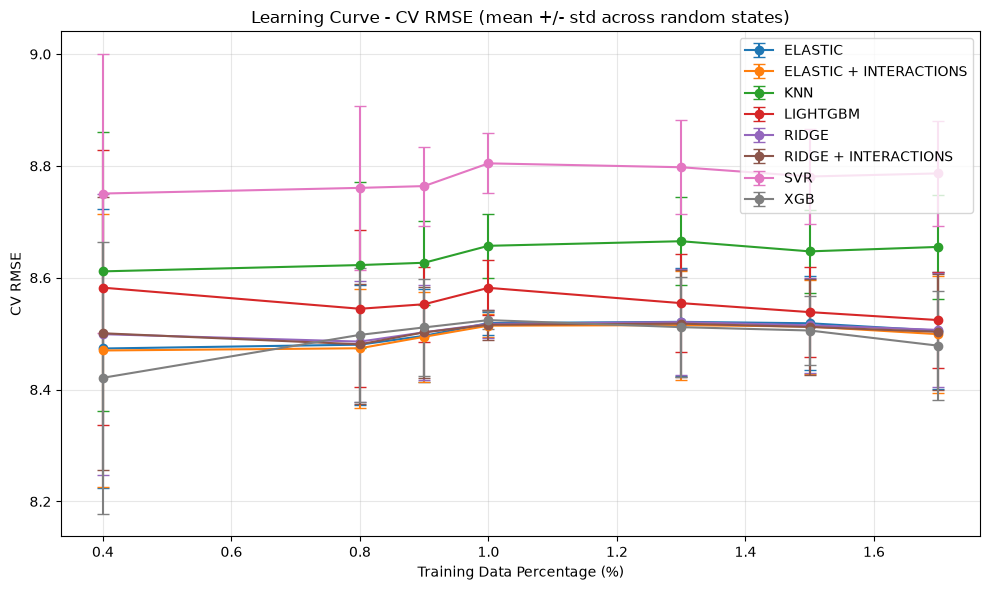

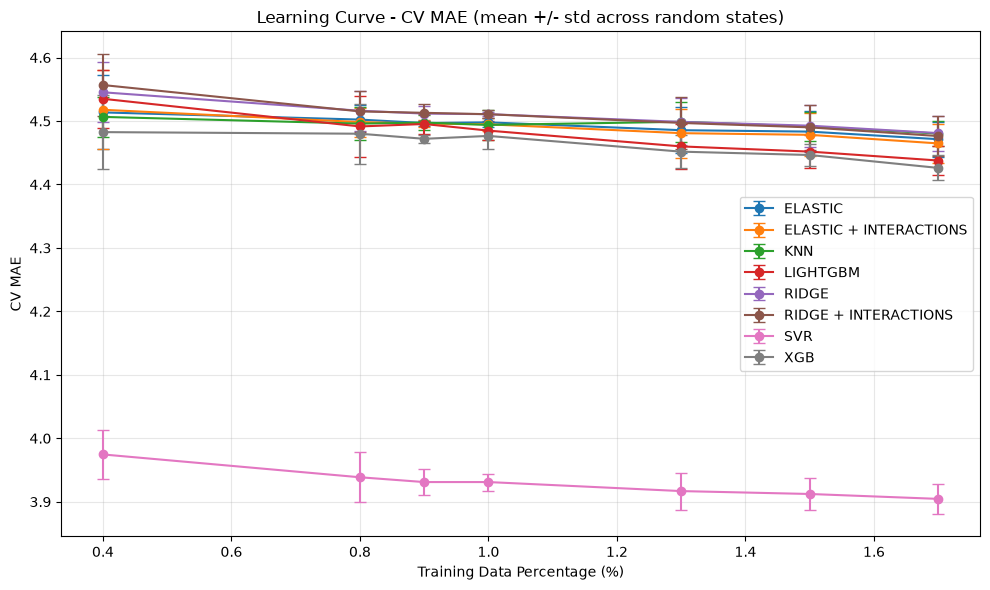

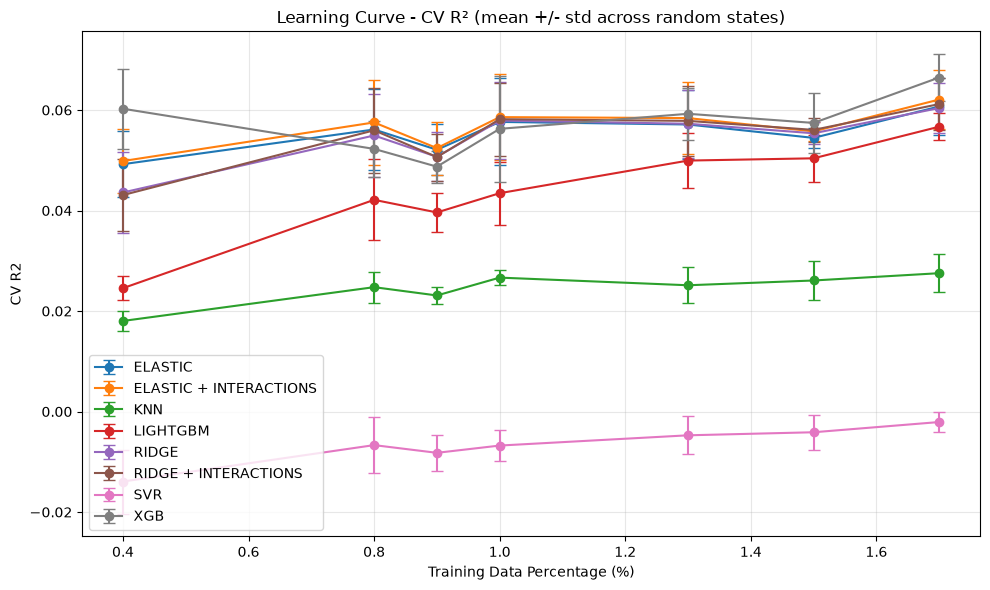

In [62]:
plot_learning_curve(
    my_results,
    metric="cv_rmse",
    title="Learning Curve - CV RMSE (mean +/- std across random states)"
)

plot_learning_curve(
    my_results,
    metric="cv_mae",
    title="Learning Curve - CV MAE (mean +/- std across random states)"
)

plot_learning_curve(
    my_results,
    metric="cv_r2",
    title="Learning Curve - CV R² (mean +/- std across random states)"
)

# Model comparison across random states

The best algorithm is the one with the lowest **mean CV RMSE** across random states. Test scores are reported, never used to choose.

In [64]:
# the largest percentage the slowest models could run, set to PCT once every algorithm has been run at it
FINAL_PCT = my_results["pct"].max()

final_results = my_results[np.isclose(my_results["pct"].astype(float), FINAL_PCT)& (my_results["random_state"].isin(RANDOM_STATES))]

summary = (
    final_results.groupby("config")
    .agg(n_states=("random_state", "nunique"),
         cv_rmse_mean=("cv_rmse", "mean"), cv_rmse_std=("cv_rmse", np.std),
         test_rmse_mean=("test_rmse", "mean"), test_rmse_std=("test_rmse", np.std),
         test_mae_mean=("test_mae", "mean"), test_r2_mean=("test_r2", "mean"))
    .sort_values("cv_rmse_mean")
)

print(f"Training percentage: {FINAL_PCT:.1%}")
print(f"Best model (lowest mean CV RMSE): {summary.index[0].upper()}")
summary.round(4)

Training percentage: 1.7%
Best model (lowest mean CV RMSE): XGB


,n_states,cv_rmse_mean,cv_rmse_std,test_rmse_mean,test_rmse_std,test_mae_mean,test_r2_mean
config,,,,,,,
xgb,3,8.4786,0.0979,8.6092,0.1801,4.4485,0.0686
elastic + interactions,3,8.4991,0.1049,8.6180,0.1828,4.4854,0.0667
ridge + interactions,3,8.5033,0.1032,8.6158,0.1764,4.4929,0.0671
elastic,3,8.5053,0.1041,8.6284,0.1841,4.4934,0.0644
ridge,3,8.5068,0.1015,8.6248,0.1768,4.4995,0.0652
lightgbm,3,8.5243,0.0851,8.6452,0.1676,4.4592,0.0607
knn,3,8.6552,0.0924,8.7729,0.1611,4.4994,0.0327
svr,3,8.7866,0.0944,8.9068,0.1807,3.9293,0.0030


In [65]:
# CV RMSE of every model for each random state, and which one was best in that random state
per_state = final_results.pivot_table(index="random_state", columns="config", values="cv_rmse")
per_state["best_model"] = per_state.idxmin(axis=1)

print("Times each model had the best CV RMSE:")
print(per_state["best_model"].value_counts().to_string())
per_state.round(4)

Times each model had the best CV RMSE:
best_model
xgb    3


config,elastic,elastic + interactions,knn,lightgbm,ridge,ridge + interactions,svr,xgb,best_model
random_state,,,,,,,,,
42,8.6115,8.6058,8.7759,8.6343,8.6118,8.6112,8.9035,8.5787,xgb
84,8.3639,8.3566,8.5516,8.4271,8.3695,8.3642,8.6723,8.3457,xgb
126,8.5406,8.5350,8.6380,8.5117,8.5390,8.5344,8.7840,8.5113,xgb


In [66]:
# best hyperparameters chosen for each model and random state
final_results.pivot_table(index="random_state", columns="config", values="best_params", aggfunc="first")

config,elastic,elastic + interactions,knn,lightgbm,ridge,ridge + interactions,svr,xgb
random_state,,,,,,,,
42,"{""model__alpha"": 0.001, ""model__l1_ratio"": 1.0...","{""model__alpha"": 0.001, ""model__l1_ratio"": 1.0...","{""model__n_neighbors"": 40, ""model__p"": 2, ""mod...","{""model__learning_rate"": 0.1, ""model__n_estima...","{""model__alpha"": 1.0}","{""model__alpha"": 1.0}","{""model__C"": 10, ""model__epsilon"": 1.0, ""model...","{""model__colsample_bytree"": 0.5, ""model__early..."
84,"{""model__alpha"": 0.001, ""model__l1_ratio"": 1.0...","{""model__alpha"": 0.001, ""model__l1_ratio"": 1.0...","{""model__n_neighbors"": 40, ""model__p"": 2, ""mod...","{""model__learning_rate"": 0.1, ""model__n_estima...","{""model__alpha"": 1.0}","{""model__alpha"": 1.0}","{""model__C"": 10, ""model__epsilon"": 1.0, ""model...","{""model__colsample_bytree"": 0.5, ""model__early..."
126,"{""model__alpha"": 0.001, ""model__l1_ratio"": 1.0...","{""model__alpha"": 0.001, ""model__l1_ratio"": 1.0...","{""model__n_neighbors"": 40, ""model__p"": 2, ""mod...","{""model__learning_rate"": 0.05, ""model__n_estim...","{""model__alpha"": 1.0}","{""model__alpha"": 1.0}","{""model__C"": 10, ""model__epsilon"": 1.0, ""model...","{""model__colsample_bytree"": 0.5, ""model__early..."


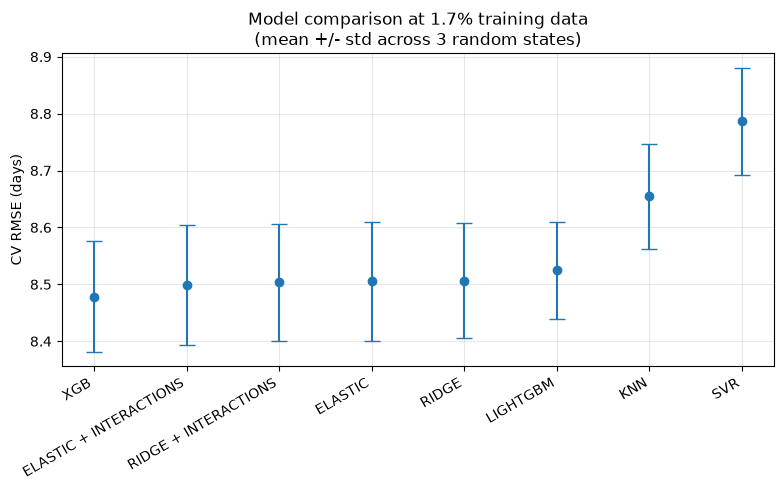

In [67]:
plt.figure(figsize=(8, 5))
plt.errorbar(
    summary.index.str.upper(),
    summary["cv_rmse_mean"],
    yerr=summary["cv_rmse_std"],
    fmt="o",
    capsize=6
)
plt.xticks(rotation=30, ha="right")
plt.ylabel("CV RMSE (days)")
plt.title(f"Model comparison at {FINAL_PCT:.1%} training data\n(mean +/- std across {final_results['random_state'].nunique()} random states)")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../figures/model_comparison_cv_rmse.png", dpi=300)
plt.show()